# Transfer Learning - MobileNetV2
MobileNetV2 pretrained on ImageNet, fine-tuned on our 8 classes. Uses the train / val / test folders.

## Setup

In [12]:
# if anything is missing:
# !pip install torch torchvision scikit-learn matplotlib

import os, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms as T
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED, IMG_SIZE, BATCH = 42, 224, 32
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"   # mac gpu
else:
    device = "cpu"
print("device:", device)

os.makedirs("reports", exist_ok=True)

device: mps


## Data

In [13]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

# same augmentation Jennifer used, only on train
train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.8, 1.25)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(0.3, 0.3, 0.2, 0.02),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder("train", transform=train_tf)
val_ds = datasets.ImageFolder("val", transform=eval_tf)
test_ds = datasets.ImageFolder("test", transform=eval_tf)
classes = train_ds.classes
n_classes = len(classes)

print(classes)
print("train", len(train_ds), "val", len(val_ds), "test", len(test_ds))

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, generator=g)
val_loader = DataLoader(val_ds, batch_size=BATCH)
test_loader = DataLoader(test_ds, batch_size=BATCH)

['apple', 'banana', 'carrot', 'cucumber', 'lemon', 'orange', 'potato', 'tomato']
train 402 val 86 test 87


## Model and training functions

In [14]:
def build_model():
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    for p in model.features.parameters():
        p.requires_grad = False                                   # freeze the pretrained part
    model.classifier[1] = nn.Linear(model.last_channel, n_classes)  # new last layer for our 8 classes
    return model.to(device)

criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total, correct, loss_sum = 0, 0, 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.set_grad_enabled(training):
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        loss_sum += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        total += len(y)
    return loss_sum / total, correct / total

def fit(model, optimizer, epochs, stage, history, patience=3, verbose=True):
    best_acc, best_state, bad_epochs = -1, None, 0
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)
        history.append(dict(stage=stage, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc))
        if verbose:
            print(f"{stage} ep {ep:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")
        if va_acc > best_acc:
            best_acc, best_state, bad_epochs = va_acc, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:   # early stopping
                if verbose:
                    print(f"{stage}: no val improvement for {patience} epochs, stopping")
                break
    model.load_state_dict(best_state)   # keep the epoch with the best val acc
    return best_acc

def train_model(lr_head=1e-3, lr_ft=1e-4, unfreeze=4, epochs_head=15, epochs_ft=25, patience=3, verbose=True):
    torch.manual_seed(SEED)
    model = build_model()
    history = []

    # stage 1: only the new last layer learns
    opt = torch.optim.Adam(model.classifier.parameters(), lr=lr_head)
    fit(model, opt, epochs_head, "head", history, patience, verbose)

    # stage 2: unfreeze the last few blocks and train everything unfrozen with a small lr
    for p in model.features[-unfreeze:].parameters():
        p.requires_grad = True
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr_ft)
    best_val = fit(model, opt, epochs_ft, "finetune", history, patience, verbose)

    return model, pd.DataFrame(history), best_val

## Train (default settings)

In [15]:
model, hist, best_val = train_model()
print("best val acc:", round(best_val, 3))

head ep  1 | train loss 1.805 acc 0.351 | val loss 1.215 acc 0.791
head ep  2 | train loss 1.081 acc 0.744 | val loss 0.730 acc 0.849
head ep  3 | train loss 0.684 acc 0.866 | val loss 0.543 acc 0.884
head ep  4 | train loss 0.544 acc 0.898 | val loss 0.421 acc 0.872
head ep  5 | train loss 0.423 acc 0.908 | val loss 0.370 acc 0.895
head ep  6 | train loss 0.412 acc 0.913 | val loss 0.328 acc 0.895
head ep  7 | train loss 0.351 acc 0.913 | val loss 0.317 acc 0.919
head ep  8 | train loss 0.283 acc 0.933 | val loss 0.276 acc 0.907
head ep  9 | train loss 0.241 acc 0.975 | val loss 0.255 acc 0.930
head ep 10 | train loss 0.271 acc 0.935 | val loss 0.248 acc 0.942
head ep 11 | train loss 0.235 acc 0.943 | val loss 0.234 acc 0.942
head ep 12 | train loss 0.221 acc 0.948 | val loss 0.224 acc 0.953
head ep 13 | train loss 0.204 acc 0.950 | val loss 0.213 acc 0.942
head ep 14 | train loss 0.201 acc 0.948 | val loss 0.202 acc 0.953
head ep 15 | train loss 0.173 acc 0.963 | val loss 0.202 acc 0

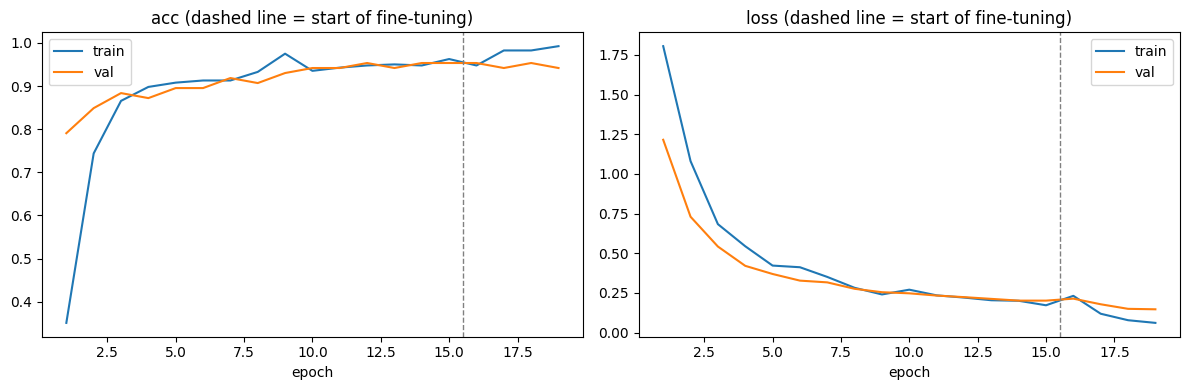

In [16]:
def plot_history(hist, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    x = range(1, len(hist) + 1)
    switch = (hist.stage == "head").sum() + 0.5
    for a, m in zip(ax, ["acc", "loss"]):
        a.plot(x, hist["train_" + m], label="train")
        a.plot(x, hist["val_" + m], label="val")
        a.axvline(switch, color="gray", ls="--", lw=1)
        a.set(title=f"{m} {title}", xlabel="epoch")
        a.legend()
    plt.tight_layout()
    plt.savefig("reports/mobilenet_history.png", dpi=150)
    plt.show()

plot_history(hist, "(dashed line = start of fine-tuning)")

## Tuning
Tries a few settings and keeps the one with the best **val** accuracy. Test set is not touched here.
Takes a while (4 full runs). Skip it if short on time, the default model from above is kept then.

In [17]:
results = []
best = dict(val=best_val, model=model, hist=hist, lr_ft=1e-4, unfreeze=4)

for lr_ft in [1e-4, 3e-4]:
    for unfreeze in [2, 6]:
        m, h, v = train_model(lr_ft=lr_ft, unfreeze=unfreeze, verbose=False)
        results.append(dict(lr_ft=lr_ft, unfreeze=unfreeze, best_val_acc=round(v, 3)))
        print(f"lr_ft={lr_ft} unfreeze={unfreeze} -> val acc {v:.3f}")
        if v > best["val"]:
            best = dict(val=v, model=m, hist=h, lr_ft=lr_ft, unfreeze=unfreeze)

results.append(dict(lr_ft=1e-4, unfreeze=4, best_val_acc=round(best_val, 3)))   # the default run
print(pd.DataFrame(results).sort_values("best_val_acc", ascending=False).to_string(index=False))
print("using:", best["lr_ft"], best["unfreeze"], "val acc", round(best["val"], 3))

model = best["model"]
torch.save(model.state_dict(), "mobilenetv2_best.pt")

lr_ft=0.0001 unfreeze=2 -> val acc 0.965
lr_ft=0.0001 unfreeze=6 -> val acc 0.977
lr_ft=0.0003 unfreeze=2 -> val acc 0.977
lr_ft=0.0003 unfreeze=6 -> val acc 0.965
 lr_ft  unfreeze  best_val_acc
0.0001         6         0.977
0.0003         2         0.977
0.0001         2         0.965
0.0003         6         0.965
0.0001         4         0.953
using: 0.0001 6 val acc 0.977


## Test set

test accuracy: 0.977
              precision    recall  f1-score   support

       apple      1.000     0.938     0.968        16
      banana      1.000     1.000     1.000        10
      carrot      0.917     1.000     0.957        11
    cucumber      1.000     1.000     1.000         9
       lemon      1.000     1.000     1.000        10
      orange      1.000     0.889     0.941         9
      potato      0.923     1.000     0.960        12
      tomato      1.000     1.000     1.000        10

    accuracy                          0.977        87
   macro avg      0.980     0.978     0.978        87
weighted avg      0.979     0.977     0.977        87



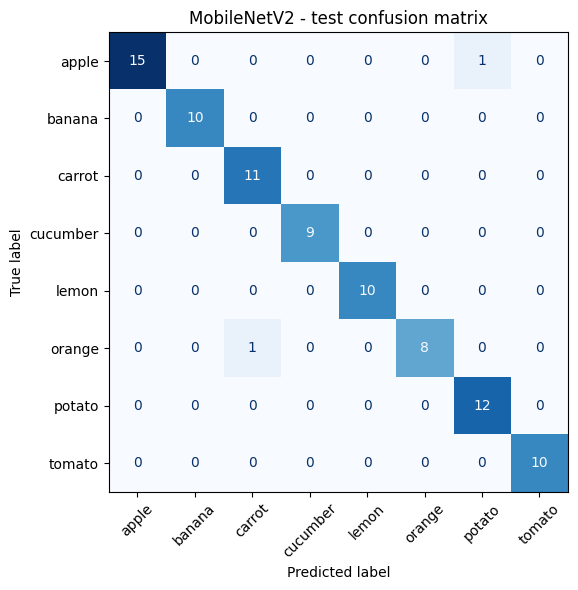

In [18]:
def predict(model, loader):
    model.eval()
    preds, probs, labels = [], [], []
    with torch.no_grad():
        for x, y in loader:
            p = F.softmax(model(x.to(device)), dim=1).cpu()
            probs.append(p); preds.append(p.argmax(1)); labels.append(y)
    return torch.cat(labels).numpy(), torch.cat(preds).numpy(), torch.cat(probs).numpy()

y_true, y_pred, y_prob = predict(model, test_loader)
print("test accuracy:", round((y_true == y_pred).mean(), 3))
print(classification_report(y_true, y_pred, labels=range(n_classes), target_names=classes, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(n_classes))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("MobileNetV2 - test confusion matrix")
plt.tight_layout()
plt.savefig("reports/mobilenet_confusion_matrix.png", dpi=150)
plt.show()

## Error analysis

  true predicted  count
 apple    potato      1
orange    carrot      1
2 wrong out of 87


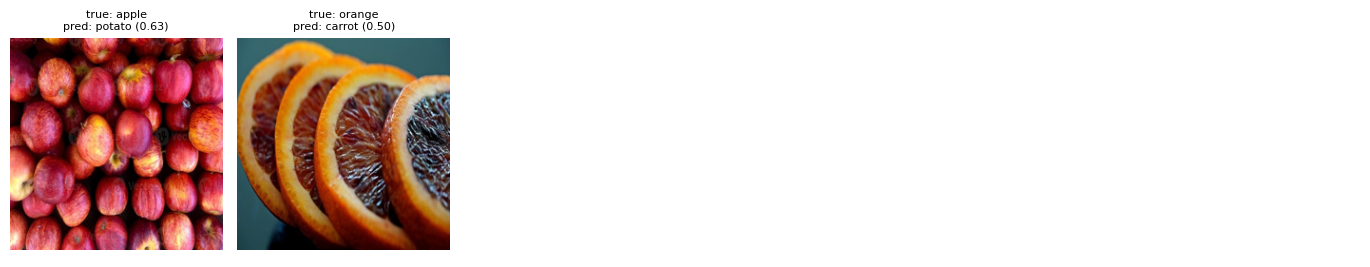

In [19]:
# which classes get mixed up the most
pairs = [(classes[i], classes[j], cm[i, j]) for i in range(n_classes) for j in range(n_classes) if i != j and cm[i, j] > 0]
print(pd.DataFrame(pairs, columns=["true", "predicted", "count"]).sort_values("count", ascending=False).to_string(index=False))

# show the wrong ones
paths = [p for p, _ in test_ds.samples]
wrong = np.where(y_true != y_pred)[0]
print(len(wrong), "wrong out of", len(y_true))

if len(wrong):
    cols = 6
    rows = int(np.ceil(len(wrong[:24]) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(cols * 2.3, rows * 2.6), squeeze=False)
    for a in ax.ravel():
        a.axis("off")
    for a, i in zip(ax.ravel(), wrong[:24]):
        a.imshow(Image.open(paths[i]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        a.set_title(f"true: {classes[y_true[i]]}\npred: {classes[y_pred[i]]} ({y_prob[i].max():.2f})", fontsize=8)
    plt.tight_layout()
    plt.savefig("reports/mobilenet_errors.png", dpi=150)
    plt.show()

## Grad-CAM
Heatmap of where the model looked. Red = the parts that pushed it toward its prediction.

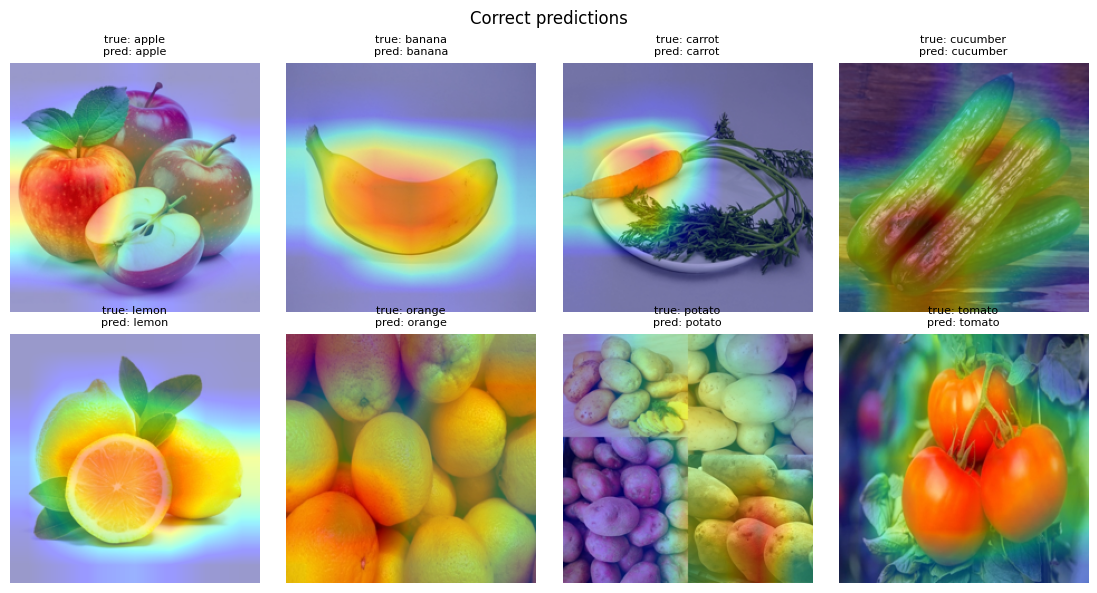

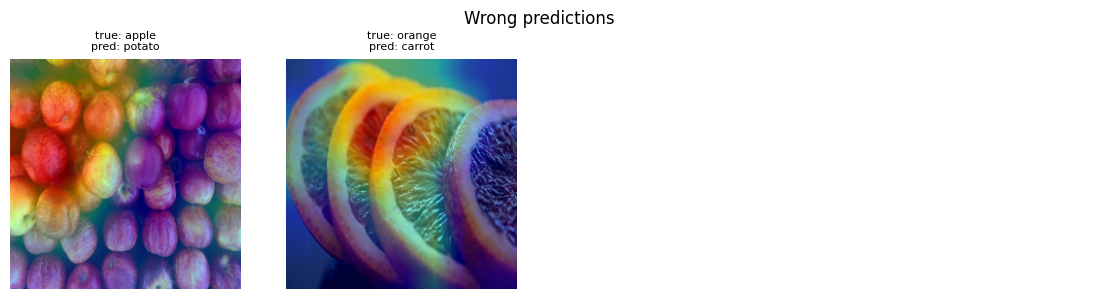

In [20]:
def grad_cam(model, x, class_idx=None):
    saved = {}
    layer = model.features[-1]   # last conv layer

    def fwd_hook(m, inp, out):
        saved["act"] = out
        out.register_hook(lambda grad: saved.__setitem__("grad", grad))

    h = layer.register_forward_hook(fwd_hook)
    model.eval()
    x = x.unsqueeze(0).to(device).requires_grad_(True)
    out = model(x)
    if class_idx is None:
        class_idx = out.argmax(1).item()
    model.zero_grad()
    out[0, class_idx].backward()
    h.remove()

    weights = saved["grad"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * saved["act"]).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    cam = cam.squeeze().detach().cpu().numpy()
    return cam / (cam.max() + 1e-8), class_idx

def show_cams(idx_list, title):
    cols = 4
    rows = int(np.ceil(len(idx_list) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(cols * 2.8, rows * 3), squeeze=False)
    for a in ax.ravel():
        a.axis("off")
    for a, i in zip(ax.ravel(), idx_list):
        x, y = test_ds[i]
        cam, pred = grad_cam(model, x)
        a.imshow(Image.open(paths[i]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        a.imshow(cam, cmap="jet", alpha=0.4)
        a.set_title(f"true: {classes[y]}\npred: {classes[pred]}", fontsize=8)
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"reports/gradcam_{title.split()[0].lower()}.png", dpi=150)
    plt.show()

# one correct example per class
right = [np.where((y_true == c) & (y_pred == c))[0] for c in range(n_classes)]
show_cams([r[0] for r in right if len(r)], "Correct predictions")

# the mistakes
if len(wrong):
    show_cams(list(wrong[:8]), "Wrong predictions")

## Summary for the report

In [21]:
summary = pd.DataFrame([dict(
    model="MobileNetV2 (fine-tuned)",
    lr_finetune=best["lr_ft"],
    blocks_unfrozen=best["unfreeze"],
    val_acc=round(best["val"], 3),
    test_acc=round((y_true == y_pred).mean(), 3),
)])
summary.to_csv("reports/mobilenet_results.csv", index=False)
summary

,model,lr_finetune,blocks_unfrozen,val_acc,test_acc
0,MobileNetV2 (fine-tuned),0.0001,6,0.977,0.977


## Extra runs (different seeds)
Trains 3 more times with the same settings as the main model, only the random seed changes.
Shows how much the result moves from run to run. Does **not** change `mobilenetv2_best.pt` or anything above.

If the notebook was restarted: run **Setup**, **Data** and **Model and training functions** first, then this cell.
Don't re-run Train or Tuning, that would replace the main model.

In [22]:
main = pd.read_csv("reports/mobilenet_results.csv").iloc[0]
lr_ft, unfreeze = float(main.lr_finetune), int(main.blocks_unfrozen)
print("settings: lr_ft", lr_ft, "unfreeze", unfreeze)

def test_acc(m):
    m.eval()
    correct = 0
    with torch.no_grad():
        for x, y in test_loader:
            correct += (m(x.to(device)).argmax(1).cpu() == y).sum().item()
    return correct / len(test_ds)

runs = [dict(model="MobileNetV2", seed="42 (main)", val_acc=main.val_acc, test_acc=main.test_acc)]
for s in [1, 7, 123]:
    SEED = s            # train_model uses SEED inside
    g.manual_seed(s)    # shuffle order
    m, h, v = train_model(lr_ft=lr_ft, unfreeze=unfreeze, verbose=False)
    t = test_acc(m)
    runs.append(dict(model="MobileNetV2", seed=s, val_acc=round(v, 3), test_acc=round(t, 3)))
    print(f"seed {s}: val {v:.3f} test {t:.3f}")
SEED = 42

runs = pd.DataFrame(runs)
runs.to_csv("reports/mobilenet_seed_runs.csv", index=False)
print(runs.to_string(index=False))
print(f"test acc mean {runs.test_acc.mean():.3f}, min {runs.test_acc.min():.3f}, max {runs.test_acc.max():.3f}")

settings: lr_ft 0.0001 unfreeze 6
seed 1: val 0.977 test 0.989
seed 7: val 0.977 test 0.977
seed 123: val 0.977 test 0.977
      model      seed  val_acc  test_acc
MobileNetV2 42 (main)    0.977     0.977
MobileNetV2         1    0.977     0.989
MobileNetV2         7    0.977     0.977
MobileNetV2       123    0.977     0.977
test acc mean 0.980, min 0.977, max 0.989
